# 03 — Train the sector-allocation agent

This notebook trains and validates one PPO sector-allocation agent per configured seed using the action mapping, decision frequency, costs, and reward function defined in `experiment_config.py`. The portfolio is valued daily.

The agent is trained only on the training period and evaluated afterward on development validation. The final holdout remains untouched.

In [1]:
from pathlib import Path
import shutil

import gymnasium as gym
from gymnasium import spaces
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from stable_baselines3 import PPO
from stable_baselines3.common.monitor import Monitor

from experiment_config import (
    EXPERIMENT_CONFIG,
    action_to_weights,
    calculate_reward,
)

## Experiment configuration

In [2]:
DATA_CONFIG = EXPERIMENT_CONFIG["data"]
ENVIRONMENT_CONFIG = EXPERIMENT_CONFIG["environment"]
TRAINING_CONFIG = EXPERIMENT_CONFIG["training"]

DEVELOPMENT_TRAIN_FRACTION = DATA_CONFIG["development_train_fraction"]
FINAL_HOLDOUT_YEARS = DATA_CONFIG["final_holdout_years"]
SCALING_WINDOW_YEARS = DATA_CONFIG["scaling_window_years"]
TRADABLE_SYMBOLS = DATA_CONFIG["tradable_symbols"]
ASSET_FEATURES = DATA_CONFIG["asset_features"]
SPY_FEATURES = DATA_CONFIG["spy_features"]
MARKET_FEATURES = DATA_CONFIG["market_features"]

TRADING_INTERVAL_DAYS = ENVIRONMENT_CONFIG["decision_frequency_days"]
ACTION_TYPE = ENVIRONMENT_CONFIG.get("action_type", "target")
TRANSACTION_COST_RATE = ENVIRONMENT_CONFIG["transaction_cost_rate"]
ANNUAL_SHORT_BORROW_RATE = ENVIRONMENT_CONFIG["annual_short_borrow_rate"]
MAXIMUM_TURNOVER_PER_DECISION = ENVIRONMENT_CONFIG.get(
    "maximum_turnover_per_decision"
)
OBSERVATION_CLIP = ENVIRONMENT_CONFIG["observation_clip"]

SEEDS = TRAINING_CONFIG["seeds"]
TRAINING_TIMESTEPS = TRAINING_CONFIG["timesteps"]
TRAIN_EPISODE_YEARS = TRAINING_CONFIG["episode_years"]
LEARNING_RATE = TRAINING_CONFIG["learning_rate"]
PPO_STEPS = TRAINING_CONFIG["ppo_steps"]
BATCH_SIZE = TRAINING_CONFIG["batch_size"]

EXPERIMENT_CONFIG

{'experiment_name': 'long_short_scaled',
 'train_model': True,
 'data': {'feature_path': '../data/processed/market_features.csv.gz',
  'development_train_fraction': 0.8,
  'final_holdout_years': 2,
  'scaling_window_years': 5,
  'tradable_symbols': ['XLB',
   'XLE',
   'XLF',
   'XLI',
   'XLK',
   'XLP',
   'XLU',
   'XLV',
   'XLY'],
  'asset_features': ['return_5d',
   'return_21d',
   'return_63d',
   'volatility_21d',
   'rolling_drawdown_63d',
   'cross_sectional_rank_return_21d',
   'market_relative_return_21d',
   'rolling_market_beta_63d'],
  'spy_features': ['return_5d',
   'return_21d',
   'return_63d',
   'volatility_21d',
   'rolling_drawdown_63d'],
  'market_features': ['sector_breadth_above_sma_63d',
   'sector_return_dispersion_21d',
   'sector_average_correlation_63d',
   'vix_level',
   'vix_return_5d']},
 'environment': {'decision_frequency_days': 5,
  'action_type': 'delta',
  'action_scale': 0.1,
  'transaction_cost_rate': 0.0005,
  'annual_short_borrow_rate': 0.01

## Prepare the chronological datasets

The train, development-validation, and final-holdout boundaries are determined before removing the scaling warm-up period. Each feature is then standardized using only its preceding five years of observations.

In [3]:
FEATURE_PATH = Path(DATA_CONFIG["feature_path"])
market_data = pd.read_csv(FEATURE_PATH, parse_dates=["date"])


def build_feature_panel(data, symbols, features):
    """Place each symbol's features in columns indexed by date."""
    return pd.concat(
        {
            symbol: (
                data.loc[data["symbol"] == symbol]
                .set_index("date")[features]
                .sort_index()
            )
            for symbol in symbols
        },
        axis=1,
    )


def scale_rolling(panel, window):
    """Standardize each observation using only preceding observations."""
    history = panel.shift(1)
    mean = history.rolling(window).mean()
    standard_deviation = history.rolling(window).std(ddof=0)
    return ((panel - mean) / standard_deviation).clip(
        -OBSERVATION_CLIP, OBSERVATION_CLIP # Numerical stability and to avoid extreme values that could destabilize training, not intended to exclude outliers
    )


def slice_dataset(dataset, mask):
    """Select one chronological period from every dataset array."""
    return {name: values[mask] for name, values in dataset.items()}

In [4]:
asset_panel = build_feature_panel(
    market_data, TRADABLE_SYMBOLS, ASSET_FEATURES
)
spy_panel = build_feature_panel(market_data, ["SPY"], SPY_FEATURES)
market_panel = (
    market_data.loc[market_data["symbol"] == "SPY"]
    .set_index("date")[MARKET_FEATURES]
    .sort_index()
)
returns_panel = (
    market_data.loc[market_data["symbol"].isin(TRADABLE_SYMBOLS)]
    .pivot(index="date", columns="symbol", values="return_1d")
    .reindex(columns=TRADABLE_SYMBOLS)
    .sort_index()
)

calendar = (
    returns_panel.dropna().index
    .intersection(asset_panel.index)
    .intersection(spy_panel.index)
    .intersection(market_panel.index)
    .sort_values()
)
asset_panel = asset_panel.reindex(calendar)
spy_panel = spy_panel.reindex(calendar)
market_panel = market_panel.reindex(calendar)
returns_panel = returns_panel.reindex(calendar)

complete_warmup = (
    asset_panel.notna().all(axis=1)
    & spy_panel.notna().all(axis=1)
    & market_panel.notna().all(axis=1)
)
first_complete_date = complete_warmup[complete_warmup].index[0]
calendar = calendar[calendar >= first_complete_date]
asset_panel = asset_panel.reindex(calendar)
spy_panel = spy_panel.reindex(calendar)
market_panel = market_panel.reindex(calendar)
returns_panel = returns_panel.reindex(calendar)

holdout_cutoff = calendar.max() - pd.DateOffset(
    years=FINAL_HOLDOUT_YEARS
)
development_calendar = calendar[calendar <= holdout_cutoff]
train_end = int(
    len(development_calendar) * DEVELOPMENT_TRAIN_FRACTION
)
train_cutoff = development_calendar[train_end - 1]

scaling_window = SCALING_WINDOW_YEARS * 252
asset_panel = scale_rolling(asset_panel, scaling_window)
spy_panel = scale_rolling(spy_panel, scaling_window)
market_panel = scale_rolling(market_panel, scaling_window)

complete_scaling = (
    asset_panel.notna().all(axis=1)
    & spy_panel.notna().all(axis=1)
    & market_panel.notna().all(axis=1)
)
calendar = calendar[complete_scaling]
asset_panel = asset_panel.reindex(calendar)
spy_panel = spy_panel.reindex(calendar)
market_panel = market_panel.reindex(calendar)
returns_panel = returns_panel.reindex(calendar)

In [5]:
train_mask = np.asarray(calendar <= train_cutoff)
validation_mask = np.asarray(
    (calendar > train_cutoff) & (calendar <= holdout_cutoff)
)
holdout_mask = np.asarray(calendar > holdout_cutoff)

full_dataset = {
    "dates": calendar.to_numpy(),
    "asset_states": asset_panel.to_numpy(dtype=np.float32),
    "spy_states": spy_panel.to_numpy(dtype=np.float32),
    "market_states": market_panel.to_numpy(dtype=np.float32),
    "asset_returns": returns_panel.to_numpy(dtype=np.float32),
}

train_data = slice_dataset(full_dataset, train_mask)
validation_data = slice_dataset(full_dataset, validation_mask)
holdout_data = slice_dataset(full_dataset, holdout_mask)

split_summary = pd.DataFrame(
    [
        {
            "split": name,
            "first_date": calendar[mask][0],
            "last_date": calendar[mask][-1],
            "dates": mask.sum(),
        }
        for name, mask in {
            "train": train_mask,
            "development validation": validation_mask,
            "locked final holdout": holdout_mask,
        }.items()
    ]
)
display(split_summary)

,split,first_date,last_date,dates
0,train,2004-04-08,2019-08-23,3871
1,development validation,2019-08-26,2024-09-30,1283
2,locked final holdout,2024-10-01,2026-09-30,501


## Portfolio mechanics

The active experiment determines whether PPO actions represent complete target weights or changes to the current portfolio. This allows target-weight and residual-action experiments to use the same environment.

In [6]:
def drift_weights(weights, asset_returns):
    """Update portfolio weights after one day of asset returns."""
    portfolio_return = weights @ asset_returns
    return (
        weights * (1 + asset_returns) / (1 + portfolio_return)
    ).astype(np.float32)

## Reward function

For portfolio weights $w_t$ and next-day asset returns $r_{t+1}$,

$$r^{net}_{t+1}=w_t^\top r_{t+1}-c\lVert w_t-w_{t^-}\rVert_1-\frac{b}{252}\sum_i(-w_{i,t})_+.$$

The exact function that converts net return into the learning reward is defined in `experiment_config.py` and copied into the trained model's directory.

In [7]:
def calculate_return_components(weights, asset_returns, turnover):
    """Calculate gross return, implementation costs, and net return."""
    gross_return = float(weights @ asset_returns)
    transaction_cost = TRANSACTION_COST_RATE * turnover
    short_exposure = float(np.maximum(-weights, 0).sum())
    short_borrow_cost = ANNUAL_SHORT_BORROW_RATE / 252 * short_exposure
    net_return = gross_return - transaction_cost - short_borrow_cost
    return {
        "gross_return": gross_return,
        "net_return": net_return,
        "transaction_cost": transaction_cost,
        "short_borrow_cost": short_borrow_cost,
        "gross_exposure": float(np.abs(weights).sum()),
        "short_exposure": short_exposure,
    }

## Weekly-decision environment

The observation contains the scaled sector, SPY, and market features and the current portfolio weights. Each action establishes the portfolio for the configured decision interval. Returns, costs, wealth, and weight drift are still calculated daily.

In [8]:
class SectorAllocationEnv(gym.Env):
    metadata = {"render_modes": []}

    def __init__(self, dataset, episode_length=None, random_start=False):
        super().__init__()
        self.dates = dataset["dates"]
        self.asset_states = dataset["asset_states"]
        self.spy_states = dataset["spy_states"]
        self.market_states = dataset["market_states"]
        self.asset_returns = dataset["asset_returns"]
        self.n_assets = self.asset_returns.shape[1]
        self.episode_length = episode_length or len(self.dates) - 1
        self.random_start = random_start

        self.action_space = spaces.Box(
            low=-1, high=1, shape=(self.n_assets,), dtype=np.float32
        )
        observation_size = (
            self.asset_states.shape[1]
            + self.spy_states.shape[1]
            + self.market_states.shape[1]
            + self.n_assets
        )
        self.observation_space = spaces.Box(
            low=-OBSERVATION_CLIP,
            high=OBSERVATION_CLIP,
            shape=(observation_size,),
            dtype=np.float32,
        )

    def observation(self):
        return np.concatenate(
            [
                self.asset_states[self.current_index],
                self.spy_states[self.current_index],
                self.market_states[self.current_index],
                self.weights,
            ]
        ).astype(np.float32)

    def reset(self, seed=None, options=None):
        super().reset(seed=seed)
        latest_start = len(self.dates) - self.episode_length - 1
        self.current_index = (
            int(self.np_random.integers(latest_start + 1))
            if self.random_start and latest_start > 0
            else 0
        )
        self.end_index = self.current_index + self.episode_length
        self.weights = np.full(
            self.n_assets, 1 / self.n_assets, dtype=np.float32
        )
        self.portfolio_value = 1.0
        return self.observation(), {}

    def step(self, action):
        decision_index = self.current_index
        target_weights = (
            action_to_weights(action, self.weights)
            if ACTION_TYPE == "delta"
            else action_to_weights(action)
        )
        if (
            ACTION_TYPE == "target"
            and MAXIMUM_TURNOVER_PER_DECISION is not None
        ):
            weight_change = target_weights - self.weights
            requested_turnover = np.abs(weight_change).sum()
            turnover_scale = MAXIMUM_TURNOVER_PER_DECISION / max(
                requested_turnover, MAXIMUM_TURNOVER_PER_DECISION
            )
            target_weights = self.weights + turnover_scale * weight_change
        period_end = min(
            decision_index + TRADING_INTERVAL_DAYS, self.end_index
        )
        total_reward = 0.0
        daily_records = []

        for next_index in range(decision_index + 1, period_end + 1):
            rebalance = next_index == decision_index + 1
            day_weights = (
                target_weights if rebalance else self.weights
            )
            turnover = float(np.abs(day_weights - self.weights).sum())
            result = calculate_return_components(
                day_weights, self.asset_returns[next_index], turnover
            )
            next_portfolio_value = (
                self.portfolio_value * (1 + result["net_return"])
            )

            reward = calculate_reward(**result, turnover=turnover)
            result["reward"] = reward
            total_reward += reward
            self.portfolio_value = next_portfolio_value

            self.weights = drift_weights(
                day_weights, self.asset_returns[next_index]
            )

            self.current_index = next_index
            daily_records.append(
                {
                    **result,
                    "date": pd.Timestamp(self.dates[next_index]),
                    "turnover": turnover,
                    "portfolio_value": self.portfolio_value,
                    "executed_weights": day_weights.copy(),
                }
            )

        truncated = self.current_index >= self.end_index
        return (
            self.observation(),
            total_reward,
            False,
            truncated,
            {"daily_records": daily_records},
        )

## Train and validate each seed

Run all cells once to process `training.seeds` in sequence. Each seed starts a fresh model and saves its results in `models/<experiment_name>/seed_<seed>/`. With `train_model=False`, each saved model is loaded for validation.


In [9]:
CONFIG_PATH = Path("experiment_config.py")
EXPERIMENT_DIRECTORY = Path("../models") / EXPERIMENT_CONFIG["experiment_name"]
validation_metrics_by_seed = {}

for SEED in SEEDS:
    MODEL_DIRECTORY = EXPERIMENT_DIRECTORY / f"seed_{SEED}"
    MODEL_PATH = MODEL_DIRECTORY / "model.zip"
    print(f"Running seed {SEED}")

    if EXPERIMENT_CONFIG["train_model"]:
        MODEL_DIRECTORY.mkdir(parents=True, exist_ok=True)
        shutil.copy2(CONFIG_PATH, MODEL_DIRECTORY / "experiment_config.py")
        split_summary.to_csv(MODEL_DIRECTORY / "data_splits.csv", index=False)

        training_episode_length = min(
            TRAIN_EPISODE_YEARS * 252, len(train_data["dates"]) - 1
        )
        training_env = Monitor(
            SectorAllocationEnv(
                train_data,
                episode_length=training_episode_length,
                random_start=True,
            )
        )
        model = PPO(
            "MlpPolicy",
            training_env,
            learning_rate=LEARNING_RATE,
            n_steps=PPO_STEPS,
            batch_size=BATCH_SIZE,
            seed=SEED,
            verbose=1,
        )
        model.learn(total_timesteps=TRAINING_TIMESTEPS)
        model.save(MODEL_PATH)
        training_env.close()

    trained_model = PPO.load(MODEL_PATH)

    validation_environment = SectorAllocationEnv(validation_data)
    observation, _ = validation_environment.reset(seed=SEED)
    validation_records = []
    done = False

    while not done:
        action, _ = trained_model.predict(observation, deterministic=True)
        observation, _, terminated, truncated, info = (
            validation_environment.step(action)
        )

        for daily_result in info["daily_records"]:
            weights = daily_result.pop("executed_weights")
            daily_result.update(
                {
                    f"weight_{symbol}": float(weight)
                    for symbol, weight in zip(TRADABLE_SYMBOLS, weights)
                }
            )
            validation_records.append(daily_result)

        done = terminated or truncated

    validation_environment.close()
    validation_results = pd.DataFrame(validation_records).set_index("date")
    validation_results.drop(columns="reward").to_csv(
        MODEL_DIRECTORY / "validation_results.csv", index_label="date"
    )

    returns = validation_results["net_return"]
    cumulative_return = (1 + returns).prod() - 1
    annualized_return = (1 + cumulative_return) ** (252 / len(returns)) - 1
    annualized_volatility = returns.std() * np.sqrt(252)
    wealth = (1 + returns).cumprod()
    drawdown = wealth / wealth.cummax() - 1

    validation_metrics = pd.Series(
        {
            "cumulative net return": cumulative_return,
            "annualized net return": annualized_return,
            "annualized volatility": annualized_volatility,
            "Sharpe ratio": returns.mean() / returns.std() * np.sqrt(252),
            "maximum drawdown": drawdown.min(),
            "annualized turnover": validation_results["turnover"].mean() * 252,
            "average gross exposure": validation_results["gross_exposure"].mean(),
            "maximum gross exposure": validation_results["gross_exposure"].max(),
            "average short exposure": validation_results["short_exposure"].mean(),
            "annualized implementation cost": (
                validation_results["transaction_cost"]
                + validation_results["short_borrow_cost"]
            ).mean() * 252,
        },
        name="PPO agent",
    )
    validation_metrics.to_csv(
        MODEL_DIRECTORY / "validation_metrics.csv", header=["value"]
    )
    display(validation_metrics.to_frame("value"))
    validation_metrics_by_seed[SEED] = validation_metrics


Running seed 42
Using cpu device
Wrapping the env in a DummyVecEnv.
---------------------------------
| rollout/           |          |
|    ep_len_mean     | 252      |
|    ep_rew_mean     | 40.1     |
| time/              |          |
|    fps             | 4526     |
|    iterations      | 1        |
|    time_elapsed    | 0        |
|    total_timesteps | 2048     |
---------------------------------
-----------------------------------------
| rollout/                |             |
|    ep_len_mean          | 252         |
|    ep_rew_mean          | 47.4        |
| time/                   |             |
|    fps                  | 3522        |
|    iterations           | 2           |
|    time_elapsed         | 1           |
|    total_timesteps      | 4096        |
| train/                  |             |
|    approx_kl            | 0.013038192 |
|    clip_fraction        | 0.117       |
|    clip_range           | 0.2         |
|    entropy_loss         | -12.8       |
|   

,value
cumulative net return,1.746682
annualized net return,0.219707
annualized volatility,0.244136
Sharpe ratio,0.936375
maximum drawdown,-0.347357
annualized turnover,16.686678
average gross exposure,1.583604
maximum gross exposure,1.646334
average short exposure,0.291802
annualized implementation cost,0.011261


## Compare seeds


In [10]:
validation_summary = pd.DataFrame(validation_metrics_by_seed).T
validation_summary.index.name = "seed"
validation_summary.to_csv(EXPERIMENT_DIRECTORY / "validation_summary.csv")
display(validation_summary)


,cumulative net return,annualized net return,annualized volatility,Sharpe ratio,maximum drawdown,annualized turnover,average gross exposure,maximum gross exposure,average short exposure,annualized implementation cost
seed,,,,,,,,,,
42,1.746682,0.219707,0.244136,0.936375,-0.347357,16.686678,1.583604,1.646334,0.291802,0.011261


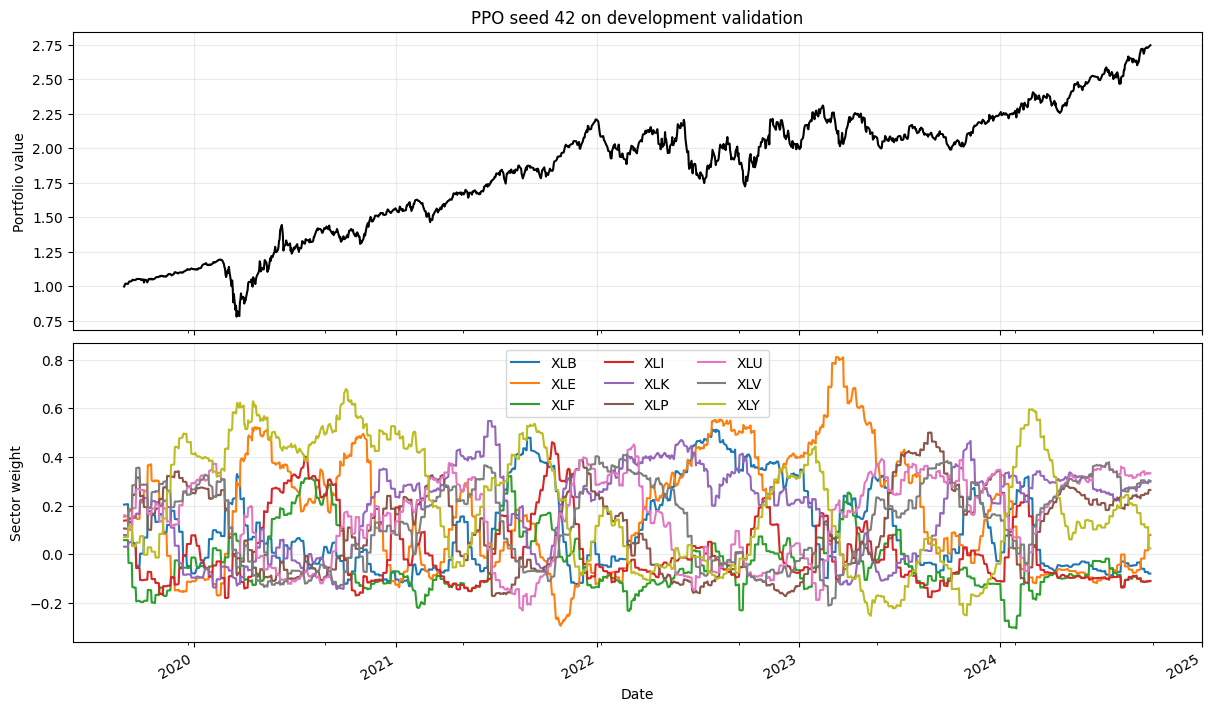

In [11]:
weight_columns = [f"weight_{symbol}" for symbol in TRADABLE_SYMBOLS]

figure, axes = plt.subplots(
    2, 1, figsize=(12, 7), sharex=True, constrained_layout=True
)
validation_results["portfolio_value"].plot(ax=axes[0], color="black")
axes[0].set_title(f"PPO seed {SEED} on development validation")
axes[0].set_ylabel("Portfolio value")

validation_results[weight_columns].rename(
    columns={f"weight_{symbol}": symbol for symbol in TRADABLE_SYMBOLS}
).plot(ax=axes[1])
axes[1].set_ylabel("Sector weight")
axes[1].set_xlabel("Date")
axes[1].legend(ncol=3)

for axis in axes:
    axis.grid(alpha=0.25)

plt.show()